In [67]:
using Pkg; Pkg.activate(@__DIR__)

  Activating project at `~/.julia/dev/drag-formation`


In [94]:
using Plots
using JLD2
using LaTeXStrings
using SatelliteToolbox
using Statistics
pgfplotsx()
# gr()

Plots.PGFPlotsXBackend()

In [69]:
const Re_mks = 6378.137 #Radius of the Earth (km)
const alt_line = 440# 550#440
const a_mks_line = Re_mks + alt_line #semi-major axis (km)


6818.137

In [70]:
data_line = load_object("Data/4sat_Jeffects_rot_eccen_control1_Line.jld2")

([0.0 0.0 0.0; 2.8783585992861933e-5 2.878358824968482e-5 2.8783588987870993e-5; … ; -0.0001583404455314802 1.9779082163326827e-5 -0.0010172932956846901; -0.0001265958990535277 8.33388877383247e-5 -0.0009199691610402551], [0.0 0.0 0.0; -6.054781898634509e-6 -6.054782372144629e-6 -6.054782527020741e-6; … ; -7.611582164557262e-7 -6.53998816879664e-7 -1.5537984932034732e-6; -7.573057823062612e-7 -6.447091005501449e-7 -1.539357515567552e-6], [0.1333333488601318 0.1333333488601318 0.1333333488601318; 0.1333333488601318 0.1333333488601318 0.1333333488601318; … ; 0.13333333334179784 0.13333333334179784 0.13333333334179784; 0.13333333333339348 0.13333333333339348 0.13333333333339348], [0.9999998898992086 0.999999957533978 0.9999999795036448; 0.9999998898992086 0.999999957533978 0.9999999795036448; … ; 0.13333333333393066 0.13333333333341657 0.13333333333336542; 0.1333333333334 0.13333333333333547 0.13333333333333414], [0.9990379701992498 0.9990379701992498 0.9990379701992498; 0.999037127861401

In [105]:
Δθhist_line, Δahist_line, u1hist_line, u2hist_line, a1hist_line, a2hist_line, θ1hist_line, θ2hist_line, Ω1hist_line, Ω2hist_line, tp_hist_line, Δθunhist_line, x_hist_line, t_hist_line, params_line, elapsed_times_line, elapsed_list_line, average_elapsed_time_line = data_line
# Δθhist_line, Δahist_line, ΔΩhist_line, u1hist_line, u2hist_line, a1hist_line, a2hist_line, θ1hist_line, θ2hist_line, Ω1hist_line, Ω2hist_line, tp_hist_line, Δθunhist_line, x_hist_line, t_hist_line, params_line = data_line

@show size(Δθhist_line)
@show size(Δahist_line)
@show size(u1hist_line)
@show size(u2hist_line)
@show size(a1hist_line)
@show size(a2hist_line)
@show size(θ1hist_line)
@show size(θ2hist_line)
@show size(Ω1hist_line)
@show size(Ω2hist_line)
@show size(tp_hist_line)
@show size(Δθunhist_line)
@show size(x_hist_line)
@show size(t_hist_line)
# @show size(params_line)


@show params_line
# @show elapsed_times_line
@show elapsed_list_line
@show average_elapsed_time_line

# Assuming elapsed_times_line is your data
Q1 = quantile(elapsed_times_line, 0.25)
Q3 = quantile(elapsed_times_line, 0.75)
IQR = Q3 - Q1

# Filter out the outliers
filtered_data = filter(x -> x <= Q3 + 1.5*IQR, elapsed_times_line)

# Now, compute the mean of the filtered data
filtered_mean = mean(filtered_data)
println("Mean of filtered data without right-skewed outliers: ", filtered_mean)

# First evaluate ΔΩ
ΔΩ_line = Ω1hist_line[1:end,:] .- Ω2hist_line[1:end,:]  # Element-wise subtraction

# Wrap the angles for ΔΩ_hist
wrapped_ΔΩ_hist_line = mod.(ΔΩ_line, 2 * π)

sample_steps = 10
downsample_line = [i % sample_steps == 0 for i = 0:length(tp_hist_line)-1]
downsample_line[1] = 0
downsample_line[2] = 1
downsample_line[end] = 1

size(Δθhist_line) = (1400, 3)
size(Δahist_line) = (1400, 3)
size(u1hist_line) = (1400, 3)
size(u2hist_line) = (1400, 3)
size(a1hist_line) = (1400, 3)
size(a2hist_line) = (1400, 3)
size(θ1hist_line) = (1400, 3)
size(θ2hist_line) = (1400, 3)
size(Ω1hist_line) = (1400, 3)
size(Ω2hist_line) = (1400, 3)
size(tp_hist_line) = (1400,)
size(Δθunhist_line) = (1400, 3)
size(x_hist_line) = (36, 261613)
size(t_hist_line) = (1, 261613)
params_line = (l_12 = 1, l_13 = 2, l_14 = 3, l_15 = 4.0, l_16 = 5.0, Δx0 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], Δaf = 0, u_min = 0.1333333333333333, u_max = 1.0, Δa_min = -0.014666763076189289, Δa_max = 0.014666763076189289, Δθf = [6.283185307179586, 12.566370614359172, 18.84955592153876, 25.132741228718345, 31.41592653589793], ΔΩf = [-0.012969814874210828, -0.025939629748421657, -0.03890944462263249, -0.051879259496843314, -0.06484907437105414])
elapsed_list_line = 22467.762
average_elapsed_time_line = 15.34034024303073
Mean of filtered data without right-skewed outliers:

2.9432794229309036


1

In [72]:
num_sat = size(Δθhist_line)[2] + 1
mylabel_line = String[]
mylabel1_line = String[]
mylabel2_line = String[]
for i = 1:num_sat
    append!(mylabel_line,["Sat. 1-"*string(i+1)])
    append!(mylabel1_line,["Sat. 1"])
    append!(mylabel2_line,["Sat. "*string(i+1)])
end

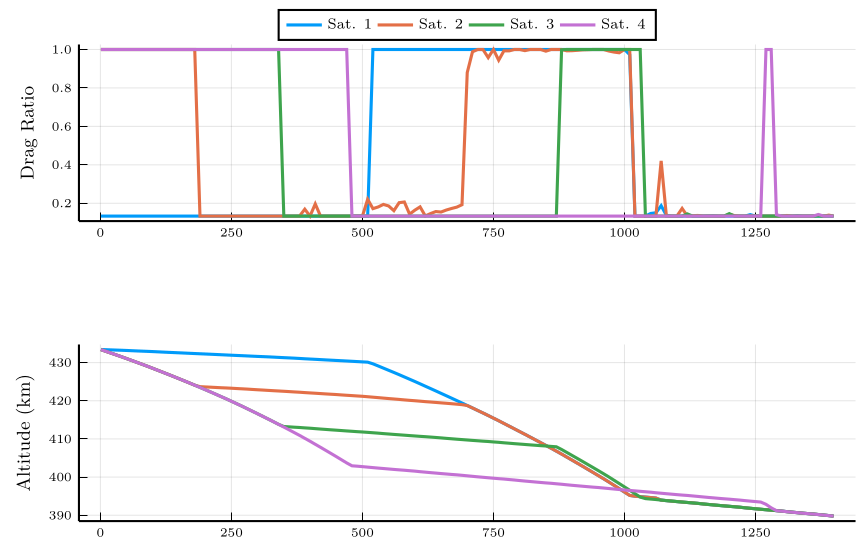

In [74]:
pl1_line = plot(tp_hist_line[downsample_line],u1hist_line[downsample_line,1],label=permutedims(mylabel1_line), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true, legend_columns=-1)#,legend=:"best") #,ls=:dot
plot!(tp_hist_line[downsample_line],u2hist_line[downsample_line,:],label=permutedims(mylabel2_line), linewidth=1.5) #,ls=:dot
plot!(xlabel=nothing, ylabel = "Drag Ratio")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)"Orbit Number"

pl2_line = plot(tp_hist_line[downsample_line],a1hist_line[downsample_line,1]*a_mks_line.-Re_mks,label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:top,legendfontsize=7, tex_output_standalone = true)#, ylim=[0, 500])#,legend=:"best") #,ls=:dot
plot!(tp_hist_line[downsample_line],a2hist_line[downsample_line,:]*a_mks_line.-Re_mks,label=nothing, linewidth=1.5)
plot!(xlabel=nothing, ylabel = "Altitude (km)")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)

pl3_line = plot(tp_hist_line[downsample_line],broadcast.(rad2deg,wrapped_ΔΩ_hist_line[downsample_line,:]),label=permutedims(mylabel_line), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel=nothing, ylabel = L"$\Delta \Omega$ (deg)")

pl4_line = plot(tp_hist_line[downsample_line],broadcast.(rad2deg,Δθhist_line[downsample_line,:]),label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel="Orbit Number", ylabel = L"$\Delta \theta$ (deg)", yticks = [90*i for i = -2:3])#"\$\\Delta \\bar{\\theta}, deg\$")


pl_line1 = plot(pl1_line,pl2_line, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_line1_pres = plot(pl1_line,pl2_line, layout = (2,1), margins=(10,:px), tex_output_standalone = false)

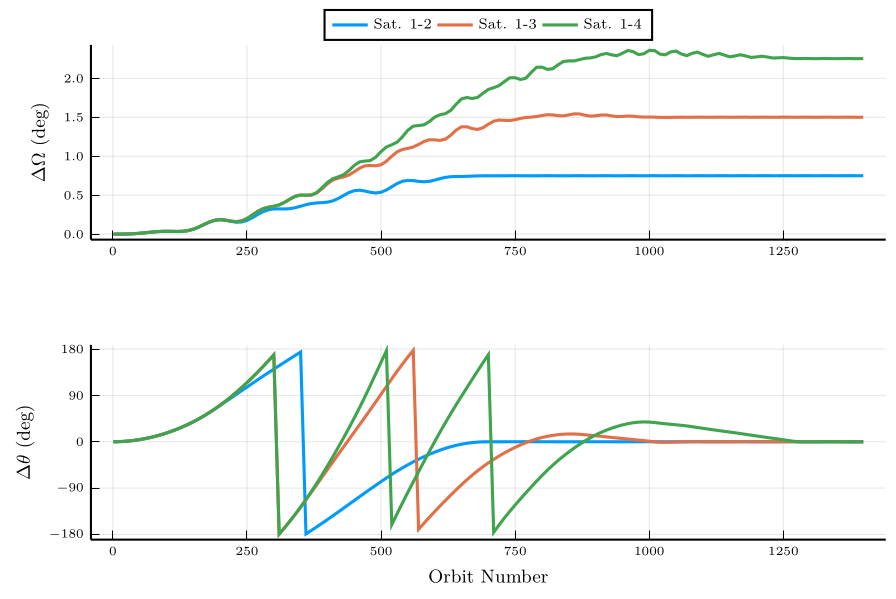

In [75]:
pl_line2 = plot(pl3_line,pl4_line, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_line2_pres = plot(pl3_line,pl4_line, layout = (2,1), tex_output_standalone = false)

In [76]:
savefig(pl_line1, "Plots/ResultsLine_1.tex")
savefig(pl_line1_pres, "Plots/ResultsLine_1.pdf")
savefig(pl_line1, "Plots/ResultsLine_1.tikz")

savefig(pl_line2, "Plots/ResultsLine_2.tex")
savefig(pl_line2_pres, "Plots/ResultsLine_2.pdf")
savefig(pl_line2, "Plots/ResultsLine_2.tikz")

"/Users/Josephine/.julia/dev/drag-formation/Plots/ResultsLine_2.tikz"

In [77]:
tp_hist_line[end]

1399.0

-------
# Box Scenario

In [43]:
const alt_box = 550# 550#440
const a_mks_box = Re_mks + alt_box #semi-major axis (km)

6928.137

In [102]:
data_box = load_object("Data/4sat_Jeffects_rot_eccen_control1_Box.jld2")

Δθhist_box, Δahist_box, u1hist_box, u2hist_box, a1hist_box, a2hist_box, θ1hist_box, θ2hist_box, Ω1hist_box, Ω2hist_box, tp_hist_box, Δθunhist_box, x_hist_box, t_hist_box, params_box, elapsed_times_box, elapsed_list_box, average_elapsed_time_box = data_box

@show size(Δθhist_box)
@show size(Δahist_box)
@show size(u1hist_box)
@show size(u2hist_box)
@show size(a1hist_box)
@show size(a2hist_box)
@show size(θ1hist_box)
@show size(θ2hist_box)
@show size(Ω1hist_box)
@show size(Ω2hist_box)
@show size(tp_hist_box)
@show size(Δθunhist_box)
@show size(x_hist_box)
@show size(t_hist_box)

# @show size(params_line)


@show params_box
@show elapsed_times_box

# Assuming elapsed_times_line is your data
Q1 = quantile(elapsed_times_box, 0.25)
Q3 = quantile(elapsed_times_box, 0.75)
IQR = Q3 - Q1


filtered_data = filter(x -> x <= Q3 + 1.5*IQR, elapsed_times_box)

# Now, compute the mean of the filtered data
filtered_mean = mean(filtered_data)
println("Mean of filtered data without right-skewed outliers: ", filtered_mean)


# First evaluate ΔΩ
ΔΩ_box = Ω1hist_box[1:end,:] .- Ω2hist_box[1:end,:]  # Element-wise subtraction

# Wrap the angles for ΔΩ_hist
wrapped_ΔΩ_hist_box = mod.(ΔΩ_box .+ 2 * π, 2 * π) .- 2 * π
# wrapped_ΔΩ_hist_box = mod.(ΔΩ_box, 2 * π)

sample_steps = 20
downsample_box = [i % sample_steps == 0 for i = 0:length(tp_hist_box)-1]
downsample_box[1] = 0
downsample_box[2] = 1
downsample_box[end] = 1
# downsample_box
println("Tot Time ", (t_hist_box[end]*tp_hist_box[end])/(60*60*24*30), " months")
println("Reached Δθf ",  broadcast.(rad2deg, Δθunhist_box[end,:]), " deg" )
println("Reached ΔΩ ",  broadcast.(rad2deg, wrapped_ΔΩ_hist_box[end,:]), " deg" )
println("Spherical distance ", sqrt.((a_mks_box*wrapped_ΔΩ_hist_box[end,:]).^2 + (a_mks_box*Δθhist_box[end,:]).^2), " km")
oe0 = rv_to_kepler(x_hist_box[1:3,end].*10^3, x_hist_box[4:6,end].*10^3)

size(Δθhist_box) = (3915, 3)
size(Δahist_box) = (3915, 3)
size(u1hist_box) = (3915, 3)
size(u2hist_box) = (3915, 3)
size(a1hist_box) = (3915, 3)
size(a2hist_box) = (3915, 3)
size(θ1hist_box) = (3915, 3)
size(θ2hist_box) = (3915, 3)
size(Ω1hist_box) = (3915, 3)
size(Ω2hist_box) = (3915, 3)
size(tp_hist_box) = (3915,)
size(Δθunhist_box) = (3915, 3)
size(x_hist_box) = (36, 751488)
size(t_hist_box) = (1, 751488)
params_box = (l_12 = 0.03, l_13 = 4.0, l_14 = 4.03, l_15 = 4.0, l_16 = 5.0, Δx0 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], Δaf = 0, u_min = 0.1333333333333333, u_max = 1.0, Δa_min = -0.01443389471080032, Δa_max = 0.01443389471080032, Δθf = [0.18849555921538758, 25.132741228718345, 25.321236787933735, 25.132741228718345, 31.41592653589793], ΔΩf = [8.424793830301574e-5, 0.011233058440402099, 0.011317306378705117, 0.011233058440402099, 0.014041323050502624])
elapsed_times_box = [32.076, 30.495, 29.505, 28.936, 28.993, 28.049, 28.018, 32.866, 31.021, 27.261, 28.978, 28.002, 31.378, 30.628, 28.7

Mean of filtered data without right-skewed outliers: 27.12305094614265
Tot Time 

8.607175925925926 months
Reached Δθf [10.742927179697746, 1440.0056078724413, 1450.8444143287334] deg
Reached ΔΩ [-0.006775245014763155, -0.6287546039277134, -0.635610278807175] deg
Spherical distance [1299.0221394361286, 76.03127717710429, 1313.544023544895] km


KeplerianElements{Float64, Float64}:
           Epoch :    0.0 (-4713-11-24T12:00:00)
 Semi-major axis : 6892.22       km
    Eccentricity :    0.00430255
     Inclination :   98.0087     °
            RAAN :  273.754      °
 Arg. of Perigee :  180.467      °
    True Anomaly :  266.52       °

In [57]:
num_sat = size(Δθhist_box)[2] + 1
mylabel_box = String[]
mylabel1_box = String[]
mylabel2_box = String[]
for i = 1:num_sat
    append!(mylabel_box,["Sat. 1-"*string(i+1)])
    append!(mylabel1_box,["Sat. 1"])
    append!(mylabel2_box,["Sat. "*string(i+1)])
end

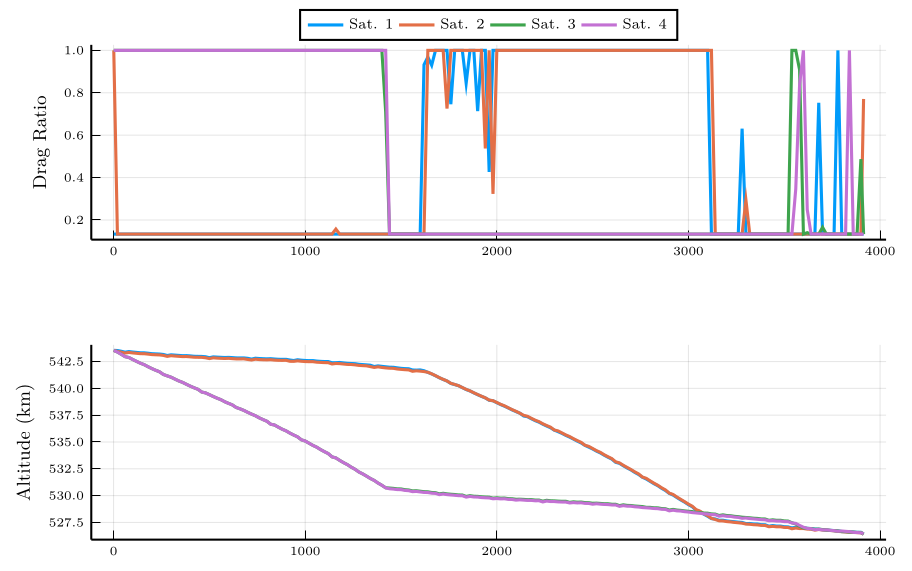

In [58]:
pl1_box = plot(tp_hist_box[downsample_box],u1hist_box[downsample_box,1],label=permutedims(mylabel1_box), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true, legend_columns=-1)#,legend=:"best") #,ls=:dot
plot!(tp_hist_box[downsample_box],u2hist_box[downsample_box,:],label=permutedims(mylabel2_box), linewidth=1.5) #,ls=:dot
plot!(xlabel=nothing, ylabel = "Drag Ratio")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)"Orbit Number"

pl2_box = plot(tp_hist_box[downsample_box],a1hist_box[downsample_box,1]*a_mks_box.-Re_mks,label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:top,legendfontsize=7, tex_output_standalone = true)#, ylim=[0, 500])#,legend=:"best") #,ls=:dot
plot!(tp_hist_box[downsample_box],a2hist_box[downsample_box,:]*a_mks_box.-Re_mks,label=nothing, linewidth=1.5)
plot!(xlabel=nothing, ylabel = "Altitude (km)")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)

pl3_box = plot(tp_hist_box[downsample_box],broadcast.(rad2deg,wrapped_ΔΩ_hist_box[downsample_box,:]),label=permutedims(mylabel_box), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel=nothing, ylabel = L"$\Delta \Omega$ (deg)")

pl4_box = plot(tp_hist_box[downsample_box],broadcast.(rad2deg,Δθhist_box[downsample_box,:]),label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel="Orbit Number", ylabel = L"$\Delta \theta$ (deg)", yticks = [90*i for i = -2:3])#"\$\\Delta \\bar{\\theta}, deg\$")


pl_box1 = plot(pl1_box,pl2_box, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_box1_pres = plot(pl1_box,pl2_box, layout = (2,1), tex_output_standalone = false)

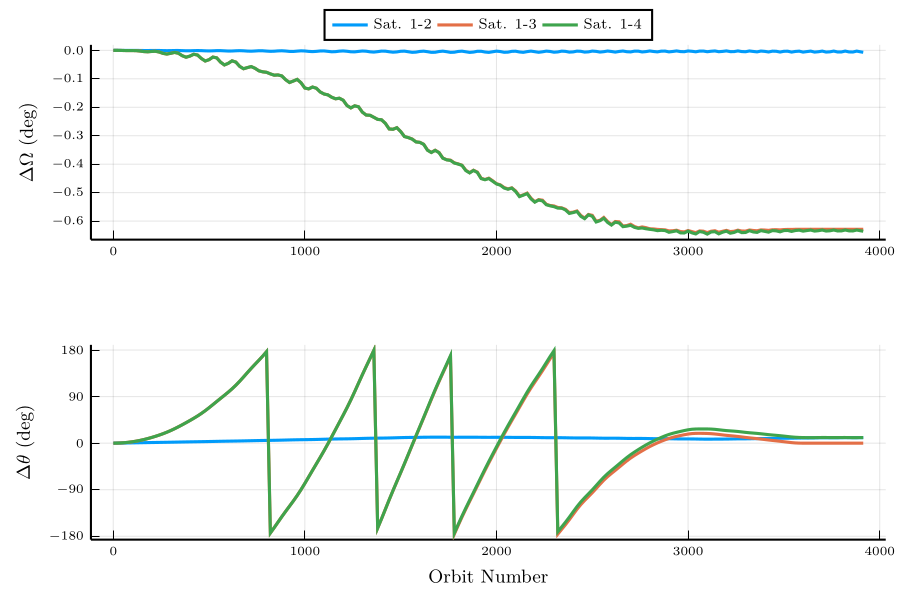

In [59]:
pl_box2 = plot(pl3_box,pl4_box, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_box2_pres = plot(pl3_box,pl4_box, layout = (2,1), tex_output_standalone = false)

In [60]:
savefig(pl_box1, "Plots/ResultsBox_1.tex")
savefig(pl_box1_pres, "Plots/ResultsBox_1.pdf")
savefig(pl_box1, "Plots/ResultsBox_1.tikz")

savefig(pl_box2, "Plots/ResultsBox_2.tex")
savefig(pl_box2_pres, "Plots/ResultsBox_2.pdf")
savefig(pl_box2, "Plots/ResultsBox_2.tikz")

"/Users/Josephine/.julia/dev/drag-formation/Plots/ResultsBox_2.tikz"

In [91]:
6892.22 - Re_mks


514.0830000000005

In [78]:
6767.87 - Re_mks

389.7330000000002

-----
# Distance between satellites

With the angle between them given as $\theta$, and the altitude of satellite 1 as $a_1$ and satellite 2 as $a_2$ the straight-line distance between the two satellites is given by the law of cosines

$$
d^2 = a_1^2 + a_2^2 - 2 a_1 a_2 \cos(\theta)
$$

In [65]:
distances_Ω_line = ((a1hist_line.*a_mks_line).*sqrt.(2 .- 2 .*cos.(wrapped_ΔΩ_hist_line)))
distances_θ_line = ((a1hist_line.*a_mks_line).*sqrt.(2 .- 2 .*cos.(Δθhist_line)))
distances_line = sqrt.(distances_Ω_line.^2 .+ distances_θ_line.^2)

p = plot(tp_hist_line[downsample_line], distances_line[downsample_line,:], label=permutedims(mylabel_line), xlabel="Orbit Number", ylabel="Distance (km)", title="Line Scenario Distances")
plot!(p, [tp_hist_line[1], tp_hist_line[end]], 500 * ones(2), style=:dash, color=:red, label="")
savefig(p, "Plots/Distance_Line.pdf")

"/Users/Josephine/.julia/dev/drag-formation/Plots/Distance_Line.pdf"

In [66]:
distances_Ω_box = ((a1hist_box.*a_mks_box).*sqrt.(2 .- 2 .*cos.(wrapped_ΔΩ_hist_box)))
distances_θ_box = ((a1hist_box.*a_mks_box).*sqrt.(2 .- 2 .*cos.(Δθhist_box)))
distances_box = sqrt.(distances_Ω_box.^2 .+ distances_θ_box.^2)

p = plot(tp_hist_box[downsample_box], distances_box[downsample_box,:], label=permutedims(mylabel_box), xlabel="Orbit Number", ylabel="Distance (km)", title="Square Scenario Distances")
plot!(p, [tp_hist_box[1], tp_hist_box[end]], 500 * ones(2), style=:dash, color=:red, label="")
savefig(p, "Plots/Distance_Box.pdf")

"/Users/Josephine/.julia/dev/drag-formation/Plots/Distance_Box.pdf"